In [1]:
import pandas as pd
import yaml 
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from decimal import Decimal
from datetime import datetime
from dateutil import parser
import networkx as nx

data exploration

In [2]:
df_users = pd.read_csv('users.csv')
df_users = pd.DataFrame(df_users)

df_books = yaml.safe_load(open('books.yaml'))
df_books = pd.DataFrame(df_books)

df_orders = pq.read_table('orders.parquet').to_pandas()
df_orders = pq.ParquetDataset('orders.parquet').read().to_pandas()

In [3]:
df_users.head()
len(df_users)
df_users.info()

df_users.duplicated().sum()


<class 'pandas.DataFrame'>
RangeIndex: 3158 entries, 0 to 3157
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   id       3158 non-null   int64
 1   name     3158 non-null   str  
 2   address  3046 non-null   str  
 3   phone    3158 non-null   str  
 4   email    3158 non-null   str  
dtypes: int64(1), str(4)
memory usage: 433.3 KB


np.int64(0)

In [4]:
print(type(df_books))
df_books.info()
print(df_books.isna().sum(), "\n")
print(df_books.duplicated().sum())

<class 'pandas.DataFrame'>
<class 'pandas.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   :id         750 non-null    int64 
 1   :title      750 non-null    str   
 2   :author     750 non-null    str   
 3   :genre      750 non-null    str   
 4   :publisher  748 non-null    str   
 5   :year       750 non-null    object
dtypes: int64(1), object(1), str(4)
memory usage: 83.3+ KB
:id           0
:title        0
:author       0
:genre        0
:publisher    2
:year         0
dtype: int64 

0


In [5]:
len(df_orders)
df_orders.info()
print(df_orders.isna().sum(), "\n")
print(df_orders.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 9714 entries, 0 to 9713
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          9714 non-null   int64
 1   user_id     9714 non-null   int64
 2   book_id     9714 non-null   int64
 3   quantity    9714 non-null   int32
 4   unit_price  9714 non-null   str  
 5   timestamp   9714 non-null   str  
 6   shipping    7349 non-null   str  
dtypes: int32(1), int64(3), str(3)
memory usage: 875.6 KB
id               0
user_id          0
book_id          0
quantity         0
unit_price       0
timestamp        0
shipping      2365
dtype: int64 

0


In [6]:
print(df_users.isna().sum(), "\n")
print(df_users.duplicated().sum())



id           0
name         0
address    112
phone        0
email        0
dtype: int64 

0


data cleaning

In [7]:
print(df_orders['unit_price'].head(10), "\n")
print(df_orders['unit_price'].unique(), "\n")
print(df_orders['timestamp'].head(20))

0      $55¢50
1     $ 50.75
2      $23.75
3     30.25 €
4    48.50USD
5    USD 22.5
6        63.$
7      $28¢00
8    EUR 46.5
9    USD22.00
Name: unit_price, dtype: str 

<ArrowStringArray>
[   '$55¢50',   '$ 50.75',    '$23.75',   '30.25 €',  '48.50USD',  'USD 22.5',
      '63.$',    '$28¢00',  'EUR 46.5',  'USD22.00',
 ...
     '$ 12.',     '$28.5',   '62. USD',    '$ 17.0', '35.25 EUR',     '39USD',
 '51.25 EUR',     '67.5€',  '72.5 EUR',     '45.5$']
Length: 5774, dtype: str 

0            20:13,31-May-2026
1     01:08:20 P.M.;2025-12-28
2       08:00:36 AM;2025-11-13
3      19:39:13 14-August-2025
4            09:46,26-Jul-2025
5          2026-06-22,13:21:39
6          2025-12-11T02:01:49
7          2026-06-17T02:46:46
8     21-OCT-2025, 09:47:23 AM
9             19:59 2025-07-22
10       19-July-2025 21:49:29
11              08:21 11/04/25
12           5-DEC-2025, 17:45
13           13:37;20-Jan-2026
14        8-Jan-2025, 02:47:33
15     10:16:45 pm, 2025-11-25
16      12/08/25;0

In [8]:
print(df_books[':year'].unique()[:20], "\n")

[1980 1995 2004 1928 2024 1831 2000 2013 1985 2011 2019 1982 2003 1986
 1983 2002 2016 1993 1979 1992] 



In [9]:
#function to change currency to usd and clean signs such as $ or eur

def convert_to_usd(unit_price):
    clean_price = unit_price.replace("$", "").replace("EUR", "").replace("€", "").replace("USD", "").replace("¢", ".").strip()

    if unit_price.startswith("€") and "¢" in unit_price:
        return Decimal(unit_price[1:].replace("¢", ".")) * Decimal("1.2")

    if unit_price.startswith("$") and "¢" in unit_price:
        return Decimal(unit_price[1:].replace("¢", "."))

    if "€" in unit_price and "¢" in unit_price:
        clean_price = unit_price.replace("€", ".").replace("¢", "")
        return Decimal(clean_price) * Decimal("1.2")

    if "$" in unit_price and "¢" in unit_price:
        clean_price = unit_price.replace("$", ".").replace("¢", "")
        return Decimal(clean_price)
    value = Decimal(clean_price)
    if "EUR" in unit_price or "€" in unit_price:
        currency = value * Decimal("1.2")
    elif "$" in unit_price or "USD" in unit_price:
        currency = value
    else:
        raise ValueError("Unsupported currency")
    
    return currency

In [10]:
print(convert_to_usd("EUR72.75"))  # test

87.300


In [11]:
df_orders['unit_price'] = df_orders['unit_price'].apply(convert_to_usd)
print(df_orders['unit_price'].head(10), "\n")
print(df_orders['unit_price'].isna().sum())

0     55.50
1     50.75
2     23.75
3    36.300
4     48.50
5      22.5
6        63
7     28.00
8     55.80
9     22.00
Name: unit_price, dtype: object 

0


In [12]:
#paid price = quentity * unit_price
df_orders['paid_price'] = df_orders['quantity'] * df_orders['unit_price']
print(df_orders[['quantity', 'unit_price', 'paid_price']].head(20))


    quantity unit_price paid_price
0          1      55.50      55.50
1          2      50.75     101.50
2          1      23.75      23.75
3          1     36.300     36.300
4          1      48.50      48.50
5          1       22.5       22.5
6          3         63        189
7          1      28.00      28.00
8          1      55.80      55.80
9          1      22.00      22.00
10         1       65.5       65.5
11         1       37.5       37.5
12         3      31.00      93.00
13         5         32        160
14         1      22.75      22.75
15         1       51.0       51.0
16         1     44.700     44.700
17         1         61         61
18         1      16.20      16.20
19         1      47.75      47.75


In [13]:
def timestamp_parser(value):
    try:
        value = str(value).strip()
        value = value.replace(",", " ").replace(";"," ")
        value = value.replace("A.M.", "AM").replace("P.M.", "PM")
        return parser.parse(value)
    except(ValueError, TypeError):
        return pd.NaT
    

In [14]:
df_orders['parsed_timestamp'] = df_orders['timestamp'].apply(timestamp_parser)
print(df_orders['parsed_timestamp'].isna().sum())

0


In [15]:
print(df_orders.columns.tolist())

['id', 'user_id', 'book_id', 'quantity', 'unit_price', 'timestamp', 'shipping', 'paid_price', 'parsed_timestamp']


In [16]:
df_orders['date'] = pd.to_datetime(df_orders['parsed_timestamp']).dt.date
print(df_orders[['parsed_timestamp', 'date']].head(5))

     parsed_timestamp        date
0 2026-05-31 20:13:00  2026-05-31
1 2025-12-28 13:08:20  2025-12-28
2 2025-11-13 08:00:36  2025-11-13
3 2025-08-14 19:39:13  2025-08-14
4 2025-07-26 09:46:00  2025-07-26


In [17]:
daily_revenue = df_orders.groupby('date')['paid_price'].sum()
top5rev = daily_revenue.sort_values(ascending = False).head(5)
print(top5rev)

date
2025-10-20    3491.840
2025-11-28    3268.260
2025-09-27    3190.498
2025-09-11    3178.228
2025-10-17    3165.176
Name: paid_price, dtype: object


In [18]:
def same_user(user1, user2):
    columns = ['name', 'address', 'phone', 'email']
    matches = 0

    for col in columns:
        if pd.notna(user1[col]) and pd.notna(user2[col]):
            if user1[col] == user2[col]:
                matches += 1

    return matches >= 3

In [19]:
G = nx.Graph()
for user_id in df_users['id']:
    G.add_node(user_id)
for i in range(len(df_users)):
    for j in range(i + 1, len(df_users)):
        user1 = df_users.iloc[i]
        user2 = df_users.iloc[j]

        if same_user(user1, user2):
            G.add_edge(user1['id'], user2['id'])

In [20]:
groups = list(nx.connected_components(G))
unique_users_count = len(groups)
print("Total user ID:", len(df_users))
print("Unique users:", unique_users_count)

Total user ID: 3158
Unique users: 2987


In [21]:
user_mapping = {}
for group in groups:
    real_id = min(group)
    for user_id in group:
        user_mapping[user_id] = real_id

df_users['real_user_id'] = df_users['id'].map(user_mapping)
print(df_users[['id', 'real_user_id']].head(10))

      id  real_user_id
0  53162         53162
1  52237         52237
2  53589         53589
3  54329         54329
4  53290         53290
5  52182         52182
6  51433         51433
7  51488         51488
8  53741         53741
9  52984         52984


In [22]:
multiple_ids = [group for group in groups if len(group) > 1]

print("Users with multiple IDs:", len(multiple_ids))
print("Examples:", multiple_ids[:15])

Users with multiple IDs: 154
Examples: [{53741, np.int64(54117)}, {54089, np.int64(51857)}, {np.int64(52187), 53639}, {np.int64(53331), 53236, np.int64(52358)}, {51805, np.int64(52423)}, {np.int64(51820), 52006}, {np.int64(53452), 53572}, {51270, np.int64(52255)}, {np.int64(53809), 53803}, {np.int64(52696), 51277}, {53354, np.int64(52743)}, {51766, np.int64(51431)}, {np.int64(51828), 53141}, {np.int64(51215), 53039}, {np.int64(53969), 52895}]


In [23]:
print("Total groups:", len(groups))
print("Multiple ID groups:", len(multiple_ids))

for group in multiple_ids[:5]:
    display(df_users[df_users['id'].isin(group)])

Total groups: 2987
Multiple ID groups: 154


,id,name,address,phone,email,real_user_id
8,53741,Jolie Nicolas,"Suite 913 787 Anderson Lodge, Lake Lauriceshir...",570 792 4430,arron@fritsch.test,53741
1551,54117,Jolie Nicolas,"Apt. 389 357 Bernier Overpass, Stephanside, MD...",570 792 4430,arron@fritsch.test,53741


,id,name,address,phone,email,real_user_id
32,54089,Solomon Prohaska,"Apt. 402 694 Thaddeus Bridge, East Marcelstad,...",(696) 518-4394,charissa@dach.test,51857
1823,51857,Ma Olson Sr.,"Apt. 402 694 Thaddeus Bridge, East Marcelstad,...",(696) 518-4394,charissa@dach.test,51857


,id,name,address,phone,email,real_user_id
34,53639,Sen. Dinorah Nolan,"Apt. 201 81757 Jewell Alley, Toyland, CT 38204",328.317.9522,ricardo.mertz@hettinger-mante.test,52187
1103,52187,Sen. Dinorah Nolan,"Apt. 201 81757 Jewell Alley, Toyland, CT 38204",420.547.0999,ricardo.mertz@hettinger-mante.test,52187


,id,name,address,phone,email,real_user_id
59,53236,Arminda Franecki,"99909 Daugherty Avenue, South Kentchester, IA ...",(675) 933-0835,dewayne@schowalter-hilpert.test,52358
843,53331,Arminda Franecki,"99909 Daugherty Avenue, South Kentchester, IA ...",(515) 448-9660,dewayne@schowalter-hilpert.test,52358
2666,52358,Arminda Franecki,"951 Raynor Spur, Chandrashire, WI 23862-6747",(515) 448-9660,dewayne@schowalter-hilpert.test,52358


,id,name,address,phone,email,real_user_id
67,51805,Ms. Gussie Labadie,"7732 Douglas Knolls, Pollichtown, HI 03869",373.620.7037,august_becker@runolfsdottir-runolfsdottir.example,51805
2460,52423,Ms. Gussie Labadie,"Apt. 897 5425 Britt Streets, Willmouth, LA 484...",373.620.7037,august_becker@runolfsdottir-runolfsdottir.example,51805


In [24]:
print("Largest group:", max(len(group) for group in groups))

Largest group: 3


In [25]:
missing_address = df_users[df_users['address'].isna()]

print("Missing addresses:", len(missing_address))
print("Unique real users:", missing_address['real_user_id'].nunique())

Missing addresses: 112
Unique real users: 112


In [26]:
print(df_books.columns.tolist())
print(df_books[':author'].head(10).to_string())

[':id', ':title', ':author', ':genre', ':publisher', ':year']
0    Myles Rohan Sr., Shirl Conn, Rep. Charley Hickle
1                   Jackie Ondricka, Jewell Harvey JD
2                                          Sana Marks
3                                  Normand Gusikowski
4                             Patsy Rice, Leola Mills
5                                     Charlena Larson
6                                           Coy Dicki
7                      Shan Armstrong, Scotty Waelchi
8                                     Vicenta Wiegand
9                                      Beverly Heaney


In [27]:
def split_names(authors):
    names = authors.split(",")
    names = [name.strip() for name in names]
    return frozenset(names)

In [28]:
df_books['authors'] = df_books[':author'].apply(split_names)
unique_authors = df_books['authors'].nunique()
print("Unique authors:", unique_authors)

Unique authors: 311


In [29]:
print(df_books[[':author', 'authors']].head(5))

                                            :author  \
0  Myles Rohan Sr., Shirl Conn, Rep. Charley Hickle   
1                 Jackie Ondricka, Jewell Harvey JD   
2                                        Sana Marks   
3                                Normand Gusikowski   
4                           Patsy Rice, Leola Mills   

                                             authors  
0  frozenset({Rep. Charley Hickle, Shirl Conn, My...  
1     frozenset({Jackie Ondricka, Jewell Harvey JD})  
2                            frozenset({Sana Marks})  
3                    frozenset({Normand Gusikowski})  
4               frozenset({Patsy Rice, Leola Mills})  


In [30]:
df_merged = df_orders.merge(df_books, left_on='book_id', right_on=':id')
author_sales = df_merged.groupby('authors')['quantity'].sum()
author_sales = author_sales.sort_values(ascending=False)

print(author_sales.head(5))

authors
frozenset({Dulcie Bode})                          169
frozenset({Cletus Parker, Ira Osinski})           151
frozenset({Carey Lubowitz})                       151
frozenset({Penelope Kreiger, Fr. Alpha Mills})    140
frozenset({Beverly Heaney})                       139
Name: quantity, dtype: int32


In [31]:
df_orders['real_user_id'] = df_orders['user_id'].map(user_mapping)

print(df_orders[['user_id', 'real_user_id', 'paid_price']].head(10))
print("Missing users:", df_orders['real_user_id'].isna().sum())

buyer_spending = df_orders.groupby('real_user_id')['paid_price'].sum()
buyer_spending = buyer_spending.sort_values(ascending=False)

print(buyer_spending.head(5))
best_buyer = buyer_spending.index[0]

buyer_ids = df_users[df_users['real_user_id'] == best_buyer]['id'].tolist()

print("Best buyer IDs:", buyer_ids)
print("Total spending:", buyer_spending.iloc[0])

   user_id  real_user_id paid_price
0    51860         51860      55.50
1    52316         52316     101.50
2    54009         54009      23.75
3    53245         52172     36.300
4    51627         51627      48.50
5    52620         52620       22.5
6    51279         51279        189
7    53261         53261      28.00
8    53865         53865      55.80
9    52387         52387      22.00
Missing users: 0
real_user_id
52895    1365.914
53615    1189.040
52526    1124.842
51198    1057.536
51179    1056.640
Name: paid_price, dtype: object
Best buyer IDs: [52895, 53969]
Total spending: 1365.914


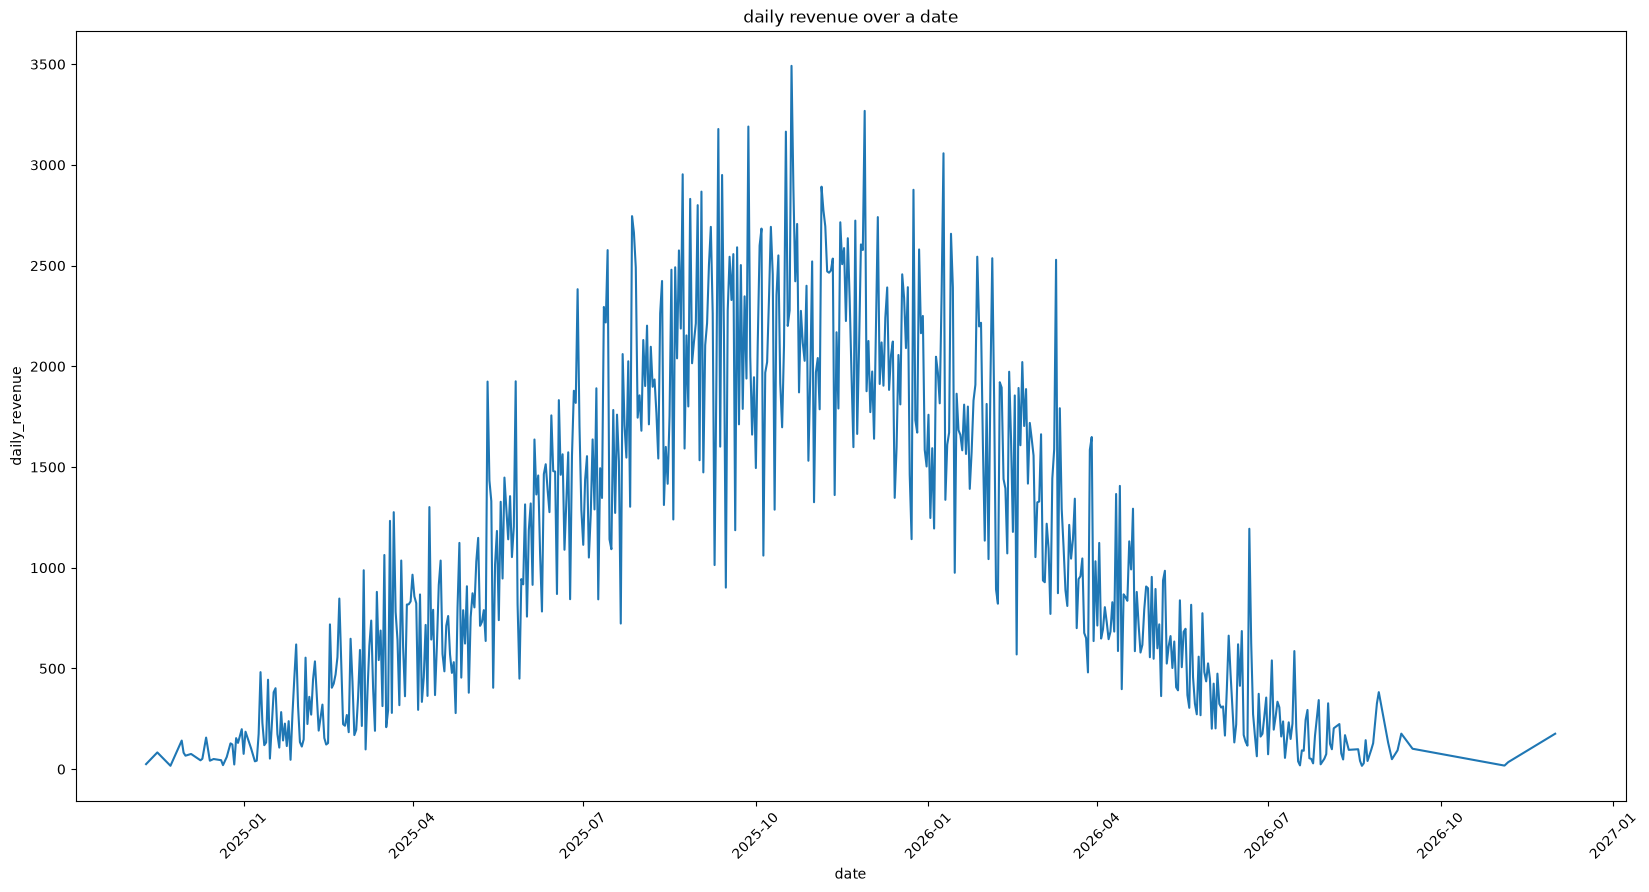

In [32]:
daily_revenue = daily_revenue.sort_index()
plt.figure(figsize=(20, 10))
plt.plot(daily_revenue.index, daily_revenue.astype(float))
plt.xlabel('date')
plt.xticks(rotation=45)
plt.ylabel('daily_revenue')
plt.title('daily revenue over a date')
plt.show()